---
# **Pokédex AI**
## **03. Modelo Final**
---

### **1. Entorno y Configuración**

In [15]:
# Bibliotecas estándar de Python.
import gc
import hashlib
import json
import math
from pathlib import Path
from time import perf_counter
from zipfile import ZIP_DEFLATED, ZipFile
from datetime import datetime, timezone

# Análisis, visualización y evaluación.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

# Construcción y entrenamiento de la red neuronal.
import tensorflow as tf
from tensorflow.keras import applications, layers

# Acceso a Google Drive.
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [16]:
# Configuración seleccionada después de los experimentos E1 a E5.
SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
DROPOUT_RATE = 0.1
FINE_TUNING_STAGE = "conv5_"
HEAD_LEARNING_RATE = 1e-3
FINE_TUNING_LEARNING_RATE = 1e-5
MAX_EPOCHS = 15
HEAD_PATIENCE = 3
FINE_TUNING_PATIENCE = 4

PHASE_NAMES = {
    "head": "Entrenamiento inicial",
    "fine_tuning": "Fine Tuning",
}

DATASET_ZIP = Path("/content/drive/MyDrive/Pokedex/prepared_dataset.zip")
WORK_DIR = Path.cwd() / "pokemon_project"
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")

RUN_DIR = WORK_DIR / RUN_ID
DATA_DIR = WORK_DIR / "training_data" / RUN_ID
CHECKPOINT_DIR = RUN_DIR / "checkpoints"
EXPORT_DIR = RUN_DIR / "export"

for directory in [DATA_DIR, CHECKPOINT_DIR, EXPORT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

EXPERIMENT_DECISIONS = [
    {"experiment": "E1. Backbones", "decision": "ResNet50 con pesos de ImageNet"},
    {"experiment": "E2. Augmentation", "decision": "Sin la política de augmentation probada"},
    {"experiment": "E3. Fine-tuning", "decision": "Ajustar conv5_* y mantener BatchNormalization congelada"},
    {"experiment": "E4. Dropout", "decision": "Dropout de 0.1 antes de softmax"},
    {"experiment": "E5. Hiperparámetros", "decision": "Batch 32; learning rates 1e-3 y 1e-5"},
]

tf.keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_columns", 15)
pd.set_option("display.max_colwidth", 75)

In [17]:
print(f"TensorFlow: {tf.__version__}")
print(f'GPU disponibles: {len(tf.config.list_physical_devices("GPU"))}')
print(f"Resultados de esta ejecución: {RUN_DIR}")
print("ZIP encontrado:", DATASET_ZIP.is_file())

TensorFlow: 2.21.0
GPU disponibles: 1
Resultados de esta ejecución: /content/pokemon_project/20261104T024855337360Z
ZIP encontrado: True


In [18]:
display(pd.DataFrame(EXPERIMENT_DECISIONS))

,experiment,decision
0,E1. Backbones,ResNet50 con pesos de ImageNet
1,E2. Augmentation,Sin la política de augmentation probada
2,E3. Fine-tuning,Ajustar conv5_* y mantener BatchNormalization congelada
3,E4. Dropout,Dropout de 0.1 antes de softmax
4,E5. Hiperparámetros,Batch 32; learning rates 1e-3 y 1e-5


### **2. Carga del Dataset Preparado**

In [19]:
def load_prepared_dataset(zip_path, destination):
    """Extraer el dataset preparado y cargar el manifiesto y las clases."""
    if not zip_path.is_file():
        raise FileNotFoundError(f"No se encontró el dataset: {zip_path}")

    with ZipFile(zip_path) as archive:
        required_files = {"splits.csv", "class_names.json"}
        if not required_files.issubset(archive.namelist()):
            raise ValueError("El ZIP debe incluir splits.csv y class_names.json.")

        # Mantener todos los archivos dentro de la carpeta de extracción.
        extraction_root = destination.resolve()
        for filename in archive.namelist():
            path = (extraction_root / filename).resolve()
            if not path.is_relative_to(extraction_root):
                raise ValueError(f"Ruta de extracción inválida: {filename}")

        archive.extractall(destination)

    manifest = pd.read_csv(destination / "splits.csv")
    class_names = json.loads((destination / "class_names.json").read_text(encoding="utf-8"))

    return manifest, class_names


def organize_splits(manifest, split_order):
    """Organizar las particiones y resumir su distribución."""
    required_columns = {"relative_path", "class_name", "class_index", "split", "group_id"}

    if not required_columns.issubset(manifest.columns):
        raise ValueError("El manifiesto no contiene todas las columnas necesarias.")

    if set(manifest["split"]) != set(split_order):
        raise ValueError("Las particiones deben ser train, val y test.")

    manifest = manifest.copy()
    manifest["class_index"] = manifest["class_index"].astype("int32")

    # Organizar las particiones con un orden fijo de imágenes.
    split_frames = {}
    for split in split_order:
        partition = manifest.loc[manifest["split"] == split]
        partition = partition.sort_values("relative_path").reset_index(drop=True)
        split_frames[split] = partition

    # Resumir las imágenes, clases y grupos de cada partición.
    summary = manifest.groupby("split").agg(
        images=("relative_path", "size"),
        classes=("class_name", "nunique"),
        groups=("group_id", "nunique"),
    )

    summary = summary.reindex(split_order)
    summary["percentage"] = 100 * summary["images"] / len(manifest)

    return split_frames, summary

In [20]:
# Cargar el dataset y organizar sus particiones.
SPLIT_ORDER = ["train", "val", "test"]

manifest, class_names = load_prepared_dataset(DATASET_ZIP, DATA_DIR)
split_frames, dataset_summary = organize_splits(manifest, SPLIT_ORDER)

NUM_CLASSES = len(class_names)
TOP_K = min(5, NUM_CLASSES)

print(f"Dataset extraído: {DATA_DIR} \n")
display(dataset_summary.round(2))
manifest_sha256 = hashlib.sha256((DATA_DIR / "splits.csv").read_bytes()).hexdigest()

Dataset extraído: /content/pokemon_project/training_data/20261104T024855337360Z 



,images,classes,groups,percentage
split,,,,
train,4853,150,4853,71.42
val,972,150,971,14.30
test,970,150,970,14.28


### **3. Preparación de los Datos**

In [21]:
def load_image_tensor(path, label):
    """Leer la imagen preparada sin repetir limpieza, escalado o redimensionamiento."""
    image = tf.io.decode_png(tf.io.read_file(path), channels=3)
    image = tf.ensure_shape(image, [IMAGE_SIZE[0], IMAGE_SIZE[1], 3])
    return image, label


def make_dataset(frame, shuffle=False):
    """Crear lotes siguiendo el manifiesto, mantener orden cuando shuffle=False."""
    paths = [str(DATA_DIR / path) for path in frame["relative_path"]]
    labels = frame["class_index"].to_numpy(dtype=np.int32)
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(load_image_tensor, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        dataset = dataset.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [22]:
train_eval_ds = make_dataset(split_frames["train"])
val_ds = make_dataset(split_frames["val"])

### **4. Arquitectura del Modelo Final**

In [23]:
def build_final_model(weights="imagenet"):
    """Construir ResNet50 con preprocesamiento integrado y Dropout antes de softmax."""
    backbone = applications.ResNet50(
        weights=weights, include_top=False, input_shape=(*IMAGE_SIZE, 3)
    )
    backbone.trainable = False
    inputs = layers.Input(shape=(*IMAGE_SIZE, 3), name="image")
    x = applications.resnet50.preprocess_input(inputs)
    x = backbone(x, training=False)
    features = layers.GlobalAveragePooling2D(name="global_pooling")(x)

    # Conservar la inicialización de la salida utilizada en los experimentos.
    classifier = layers.Dense(NUM_CLASSES, activation="softmax", name="species")
    classifier(features)
    x = layers.Dropout(DROPOUT_RATE, seed=SEED, name="dropout")(features)
    outputs = classifier(x)
    return tf.keras.Model(inputs, outputs, name="pokemon_resnet50_final")


def configure_fine_tuning(model):
    """Habilitar conv5_* y la salida, conservando BatchNormalization congelada."""
    model.trainable = True
    backbone = model.get_layer("resnet50")
    backbone.trainable = True
    for layer in backbone.layers:
        belongs_to_stage = layer.name.startswith(FINE_TUNING_STAGE)
        is_batch_norm = isinstance(layer, layers.BatchNormalization)
        layer.trainable = belongs_to_stage and not is_batch_norm
    return model


def compile_model(model, learning_rate):
    """Crear un optimizador nuevo para cada fase de entrenamiento."""
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=[
            tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
            tf.keras.metrics.SparseTopKCategoricalAccuracy(k=TOP_K, name=f"top_{TOP_K}_accuracy"),
        ],
    )

In [24]:
# Crear un modelo nuevo con los pesos iniciales de ImageNet.
tf.keras.backend.clear_session()
gc.collect()
tf.keras.utils.set_random_seed(SEED)

model_final = build_final_model()
model_final.summary()

Model: "pokemon_resnet50_final"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 224, 224,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ image[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ image[0][0]       │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ image[0][0]       │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_pooling      │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ global_pooling[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ species (Dense)     │ (None, 150)       │    307,350 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,895,062 (91.15 MB)

 Trainable params: 307,350 (1.17 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

### **5. Entrenamiento del Modelo**

In [25]:
def create_callbacks(checkpoint_path, patience):
    """Guardar la mejor época y detener entrenamientos sin mejora o con pérdida inválida."""
    return [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=patience,
            restore_best_weights=True,
        ),
        tf.keras.callbacks.TerminateOnNaN(),
    ]


def train_model(model, train_dataset, val_dataset, checkpoint_path, epochs, patience):
    """Entrenar el modelo y devolver su historial, duración y mejor época."""
    callbacks = create_callbacks(checkpoint_path, patience)

    # Medir el tiempo del entrenamiento, incluida la validación.
    start = perf_counter()
    history = model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=epochs,
        callbacks=callbacks,
        verbose=2,
        shuffle=False,  # El dataset de entrenamiento ya está mezclado.
    )
    training_seconds = perf_counter() - start

    # Convertir el historial a valores compatibles con la exportación JSON.
    history_values = {
        metric: [float(value) for value in values]
        for metric, values in history.history.items()
    }

    if not checkpoint_path.is_file() or not np.isfinite(
        history_values["val_loss"]
    ).all():
        raise RuntimeError("No se obtuvo un checkpoint válido.")

    best_epoch = int(np.argmin(history_values["val_loss"])) + 1
    return history_values, training_seconds, best_epoch

In [26]:
def make_protocol():
    """Registrar la configuración fija seleccionada mediante validación."""
    return {
        "seed": SEED, "input_shape": [*IMAGE_SIZE, 3], "input_range": [0, 255],
        "batch_size": BATCH_SIZE, "optimizer": "Adam", "checkpoint_monitor": "val_loss",
        "pretrained_weights": "imagenet", "classifier": "GlobalAveragePooling2D + Dropout + Dense softmax",
        "dropout": True, "dropout_rate": DROPOUT_RATE, "augmentation": False,
        "fine_tuning": True, "trainable_stage": FINE_TUNING_STAGE,
        "batch_normalization_frozen": True, "class_count": NUM_CLASSES,
        "tensorflow_version": tf.__version__,
        "split_counts": {split: len(frame) for split, frame in split_frames.items()},
        "preprocessing": "RGB to BGR and ImageNet channel means subtracted",
        "phase_1": {"learning_rate": HEAD_LEARNING_RATE, "maximum_epochs": MAX_EPOCHS,
                    "early_stopping_patience": HEAD_PATIENCE},
        "phase_2": {"learning_rate": FINE_TUNING_LEARNING_RATE, "maximum_epochs": MAX_EPOCHS,
                    "early_stopping_patience": FINE_TUNING_PATIENCE},
    }


def train_phase(model, name, learning_rate, patience):
    """Entrenar una fase y devolver los datos de su mejor checkpoint."""
    compile_model(model, learning_rate)
    checkpoint = CHECKPOINT_DIR / f"best_{name}.keras"
    train_ds = make_dataset(split_frames["train"], shuffle=True)
    history, seconds, epoch = train_model(
        model, train_ds, val_ds, checkpoint, MAX_EPOCHS, patience
    )
    phase = {"history": history, "best_epoch": epoch,
             "epochs_completed": len(history["loss"]), "training_seconds": seconds}
    return checkpoint, phase

In [27]:
def train_final_model(model):
    """Entrenar el modelo creado en arquitectura y continuar con el ajuste fino."""
    protocol = make_protocol()

    # Entrenar la capa que asigna las clases, conservando los pesos de ResNet50.
    print("Fase 1: Entrenamiento inicial")
    head_checkpoint, head = train_phase(model, "head", HEAD_LEARNING_RATE, HEAD_PATIENCE)
    del model
    tf.keras.backend.clear_session()
    gc.collect()

    # Continuar únicamente desde la primera fase de esta ejecución.
    tf.keras.utils.set_random_seed(SEED)
    model = tf.keras.models.load_model(head_checkpoint, compile=False)
    configure_fine_tuning(model)
    print("Fase 2: Fine tuning")
    final_checkpoint, fine = train_phase(
        model, "fine_tuning", FINE_TUNING_LEARNING_RATE, FINE_TUNING_PATIENCE
    )
    del model
    tf.keras.backend.clear_session()
    gc.collect()

    fit_results = {
        "protocol": protocol, "manifest_sha256": manifest_sha256,
        "phases": {"head": head, "fine_tuning": fine},
        "training_seconds": head["training_seconds"] + fine["training_seconds"],
        "source": "trained_from_imagenet",
    }
    selected_model = tf.keras.models.load_model(final_checkpoint, compile=False)
    return selected_model, fit_results

In [28]:
# Entrenar ambas fases utilizando el modelo creado en arquitectura.
selected_model, fit_results = train_final_model(model_final)
del model_final
_ = gc.collect()

Fase 1: Entrenamiento inicial
Epoch 1/15
152/152 - 52s - 342ms/step - accuracy: 0.3507 - loss: 3.1895 - top_5_accuracy: 0.5605 - val_accuracy: 0.6492 - val_loss: 1.5460 - val_top_5_accuracy: 0.8549
Epoch 2/15
152/152 - 27s - 180ms/step - accuracy: 0.8490 - loss: 0.7824 - top_5_accuracy: 0.9629 - val_accuracy: 0.7510 - val_loss: 1.0676 - val_top_5_accuracy: 0.9115
Epoch 3/15
152/152 - 27s - 181ms/step - accuracy: 0.9448 - loss: 0.3668 - top_5_accuracy: 0.9928 - val_accuracy: 0.7984 - val_loss: 0.8941 - val_top_5_accuracy: 0.9331
Epoch 4/15
152/152 - 27s - 180ms/step - accuracy: 0.9794 - loss: 0.2034 - top_5_accuracy: 0.9992 - val_accuracy: 0.8035 - val_loss: 0.8562 - val_top_5_accuracy: 0.9311
Epoch 5/15
152/152 - 26s - 171ms/step - accuracy: 0.9897 - loss: 0.1257 - top_5_accuracy: 0.9998 - val_accuracy: 0.8138 - val_loss: 0.7855 - val_top_5_accuracy: 0.9403
Epoch 6/15
152/152 - 25s - 167ms/step - accuracy: 0.9942 - loss: 0.0876 - top_5_accuracy: 1.0000 - val_accuracy: 0.8189 - val_loss

In [29]:
def summarize_training(phases):
    """Resumir las épocas y la duración de cada fase de entrenamiento."""
    rows = []
    for name, phase in phases.items():
        rows.append({
            "phase": PHASE_NAMES[name],
            "best_epoch": phase["best_epoch"],
            "epochs": phase["epochs_completed"],
            "minutes": phase["training_seconds"] / 60,
        })
    return pd.DataFrame(rows)

In [30]:
display(summarize_training(fit_results["phases"]).round(2))

,phase,best_epoch,epochs,minutes
0,Entrenamiento inicial,10,13,6.16
1,Fine Tuning,3,7,4.25


In [31]:
def plot_training_history(phase, title):
    """Mostrar la pérdida y la exactitud de una sola fase de entrenamiento."""
    history = phase["history"]
    epochs = np.arange(1, len(history["loss"]) + 1)
    figure, axes = plt.subplots(2, 1, figsize=(6, 8))

    axes[0].plot(epochs, history["loss"], label="Entrenamiento")
    axes[0].plot(epochs, history["val_loss"], label="Validación")
    axes[0].set_title("Pérdida durante el entrenamiento")
    axes[0].set_ylabel("Cross Entropy")

    axes[1].plot(epochs, np.array(history["accuracy"]) * 100, label="Entrenamiento")
    axes[1].plot(epochs, np.array(history["val_accuracy"]) * 100, label="Validación")
    axes[1].set_title("Accuracy durante el entrenamiento")
    axes[1].set_ylabel("Accuracy (%)")

    for axis in axes:
        axis.axvline(phase["best_epoch"], color="gray", linestyle="--", label="Mejor época")
        axis.set_xlabel("Época")
        axis.legend()

    figure.suptitle(title)
    figure.tight_layout()
    plt.show()
    plt.close(figure)

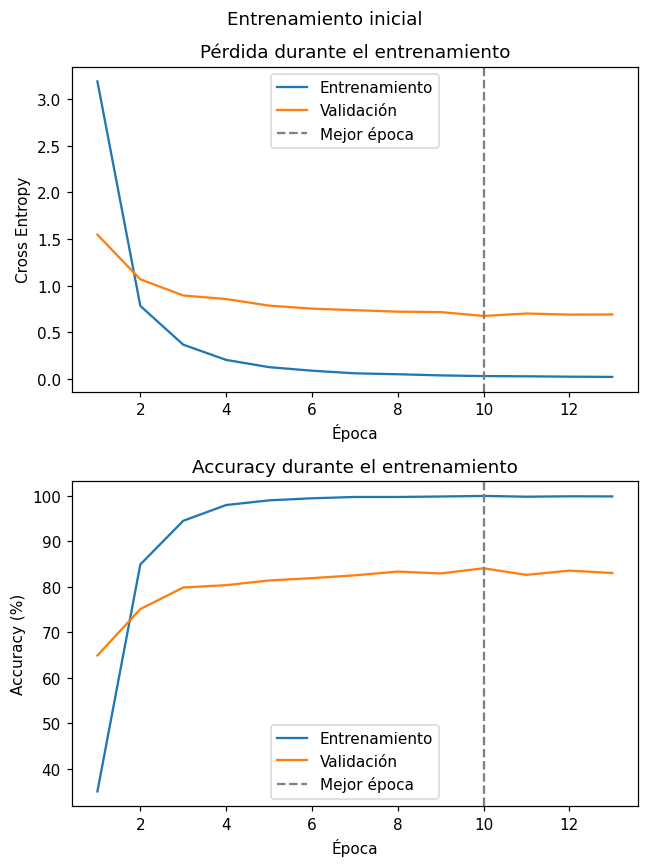

In [32]:
plot_training_history(fit_results["phases"]["head"], PHASE_NAMES["head"])

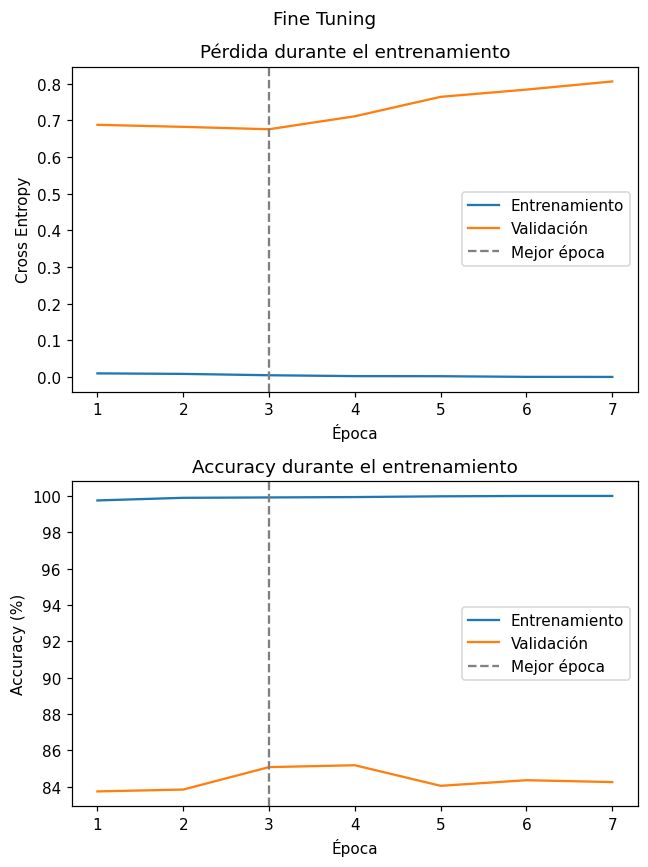

In [33]:
plot_training_history(fit_results["phases"]["fine_tuning"], PHASE_NAMES["fine_tuning"])

### **6. Selección del Modelo Final**

In [34]:
# El entrenamiento carga el checkpoint de menor pérdida de validación del ajuste fino.
final_phase = fit_results["phases"]["fine_tuning"]
best_epoch = final_phase["best_epoch"]
best_index = best_epoch - 1
history_values = final_phase["history"]

selection_summary = pd.DataFrame({
    "model": ["ResNet50 final"],
    "best_epoch": [best_epoch],
    "val_loss_at_best_epoch": [history_values["val_loss"][best_index]],
    "val_accuracy_at_best_epoch": [history_values["val_accuracy"][best_index]],
    "parameters": [selected_model.count_params()],
})

display(selection_summary)

,model,best_epoch,val_loss_at_best_epoch,val_accuracy_at_best_epoch,parameters
0,ResNet50 final,3,0.675807,0.850823,23895062


### **7. Evaluación del Modelo Final**

In [35]:
def calculate_metrics(labels, probabilities):
    """Evaluar clasificación multiclase con el mismo orden de etiquetas del manifiesto."""
    if probabilities.shape != (len(labels), NUM_CLASSES):
        raise ValueError("Las predicciones no coinciden con las filas o las clases esperadas.")

    if not np.isfinite(probabilities).all():
        raise ValueError("Hay predicciones no finitas.")

    predicted = probabilities.argmax(axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predicted,
        labels=np.arange(NUM_CLASSES),
        average="macro",
        zero_division=0,
    )

    top_indices = np.argsort(probabilities, axis=1)[:, -TOP_K:]
    top_k_accuracy = np.any(top_indices == labels[:, None], axis=1).mean()
    losses = tf.keras.losses.sparse_categorical_crossentropy(labels, probabilities)

    return {
        "loss": float(tf.reduce_mean(losses)),
        "accuracy": float(accuracy_score(labels, predicted)),
        f"top_{TOP_K}_accuracy": float(top_k_accuracy),
        "precision_macro": float(precision),
        "recall_macro": float(recall),
        "f1_macro": float(f1),
    }

In [36]:
def get_class_metrics(labels, predicted, class_names, top_n=10):
    """Calcular las métricas por clase e identificar las de menor F1."""
    report = classification_report(
        labels,
        predicted,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )

    metrics = pd.DataFrame(report).T.loc[class_names].copy()
    metrics.index.name = "class_name"
    metrics["support"] = metrics["support"].astype(int)

    worst_classes = metrics.sort_values(["f1-score", "recall"]).head(top_n)
    return report, metrics, worst_classes


def evaluate_final_model(model):
    """Evaluar train, val y test con los pesos ya seleccionados y el orden del manifiesto."""
    metrics, predictions, reports, matrices = {}, {}, {}, {}
    for split in SPLIT_ORDER:
        dataset = make_dataset(split_frames[split])
        probabilities = model.predict(dataset, verbose=0)
        labels = split_frames[split]["class_index"].to_numpy(dtype=np.int32)
        predicted = probabilities.argmax(axis=1)
        metrics[split] = calculate_metrics(labels, probabilities)
        predictions[split] = probabilities
        if split in ["val", "test"]:
            reports[split], _, _ = get_class_metrics(labels, predicted, class_names)
            matrices[split] = confusion_matrix(labels, predicted, labels=np.arange(NUM_CLASSES))
    return metrics, predictions, reports, matrices

In [37]:
# La prueba se utiliza una vez terminada la selección de arquitectura e hiperparámetros.
evaluation_metrics, predictions_by_split, reports_by_split, matrices_by_split = evaluate_final_model(selected_model)
metrics_table = pd.DataFrame(evaluation_metrics).T.reindex(SPLIT_ORDER)
metrics_table.index.name = "split"
display(metrics_table.round(4))

,loss,accuracy,top_5_accuracy,precision_macro,recall_macro,f1_macro
split,,,,,,
train,0.0025,0.9994,1.0000,0.9993,0.9989,0.9990
val,0.6758,0.8508,0.9527,0.8633,0.8559,0.8446
test,0.7284,0.8299,0.9495,0.8379,0.8317,0.8204


### **8. Análisis de Errores**

In [38]:
def summarize_errors(split, top_n=10):
    """Obtener las métricas por clase y las clases con menor F1 en una partición."""
    report = reports_by_split[split]
    class_metrics = pd.DataFrame(report).T.loc[class_names].copy()
    class_metrics.index.name = "class_name"
    class_metrics["support"] = class_metrics["support"].astype(int)
    worst_classes = class_metrics.sort_values(["f1-score", "recall"]).head(top_n)
    return class_metrics, worst_classes

In [39]:
ANALYSIS_SPLIT = "test"
per_class_metrics, worst_classes = summarize_errors(ANALYSIS_SPLIT)
print(f"Partición analizada: {ANALYSIS_SPLIT}")
display(worst_classes.round(4))

Partición analizada: test


,precision,recall,f1-score,support
class_name,,,,
Marowak,0.0000,0.0000,0.0000,6
Geodude,0.6667,0.2857,0.4000,7
Abra,0.5000,0.5000,0.5000,2
Growlithe,0.5000,0.5000,0.5000,2
Drowzee,0.7500,0.4286,0.5455,7
Magnemite,1.0000,0.4000,0.5714,5
Poliwrath,0.6667,0.5000,0.5714,4
Venusaur,0.4000,1.0000,0.5714,4
Rapidash,0.5000,0.7143,0.5882,7


In [40]:
def plot_class_confusions(matrix, class_names, selected_classes):
    """Mostrar las confusiones de las clases seleccionadas, incluyendo Otras."""
    indices = [class_names.index(name) for name in selected_classes]
    selected_rows = matrix[indices]
    selected_columns = selected_rows[:, indices]

    # Agrupar las predicciones hacia clases fuera del recorte.
    totals = selected_rows.sum(axis=1, keepdims=True)
    others = totals[:, 0] - selected_columns.sum(axis=1)
    counts = np.column_stack([selected_columns, others])
    proportions = np.divide(
        counts, totals,
        out=np.zeros_like(counts, dtype=float),
        where=totals != 0,
    )

    figure, axis = plt.subplots(figsize=(12, 7))
    image = axis.imshow(proportions, cmap="Blues", vmin=0, vmax=1)

    column_names = list(selected_classes) + ["Otras"]
    axis.set_xticks(
        range(len(column_names)), column_names, rotation=55, ha="right"
    )
    axis.set_yticks(range(len(selected_classes)), selected_classes)
    axis.set_xlabel("Clase predicha")
    axis.set_ylabel("Clase real")
    axis.set_title("Confusiones de las clases con menor F1")
    figure.colorbar(image, ax=axis, label="Proporción de imágenes")

    # Anotar únicamente las celdas con observaciones.
    for (row, column), value in np.ndenumerate(proportions):
        if value > 0:
            axis.text(
                column, row, f"{value:.0%}",
                ha="center", va="center",
                color="white" if value > 0.5 else "black",
                fontsize=8,
            )

    figure.tight_layout()
    plt.show()
    plt.close(figure)

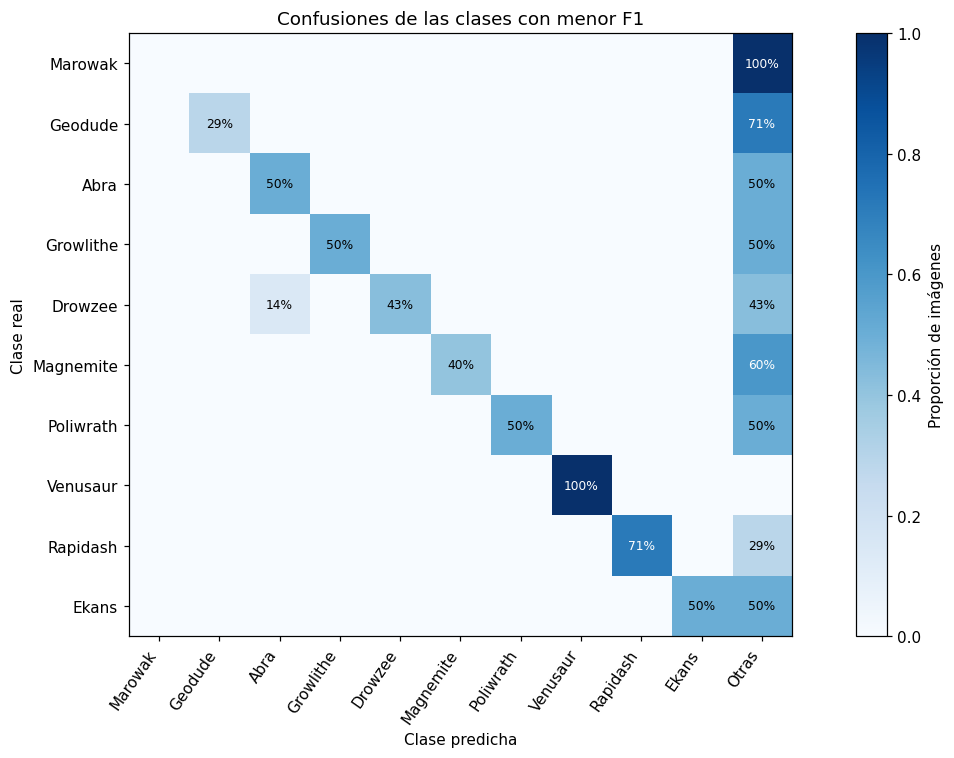

In [41]:
plot_class_confusions(
    matrices_by_split[ANALYSIS_SPLIT], class_names, worst_classes.index
)

In [42]:
def show_prediction_errors(frame, probabilities, class_names, data_dir, top_n=8):
    """Mostrar errores con las puntuaciones softmax más altas."""
    labels = frame["class_index"].to_numpy(dtype=np.int32)
    predicted = probabilities.argmax(axis=1)
    error_indices = np.flatnonzero(predicted != labels)

    if len(error_indices) == 0:
        print("No se encontraron errores en esta partición.")
        return

    # Ordenar los errores por la puntuación asignada a la clase predicha.
    scores = probabilities[error_indices].max(axis=1)
    shown_indices = error_indices[np.argsort(-scores)[:top_n]]

    columns = 4
    rows = math.ceil(len(shown_indices) / columns)
    figure, axes = plt.subplots(rows, columns, figsize=(13, 3.5 * rows), squeeze=False)

    for axis in axes.flat:
        axis.axis("off")

    for axis, index in zip(axes.flat, shown_indices):
        image_path = data_dir / frame.iloc[index]["relative_path"]
        with Image.open(image_path) as image:
            axis.imshow(np.asarray(image.convert("RGB")))

        true_name = class_names[labels[index]]
        predicted_name = class_names[predicted[index]]
        score = probabilities[index, predicted[index]]

        axis.set_title(
            f"Real: {true_name}\nPredicha: {predicted_name}\nSoftmax: {score:.3f}",
            fontsize=9,
        )

    figure.tight_layout()
    plt.show()
    plt.close(figure)

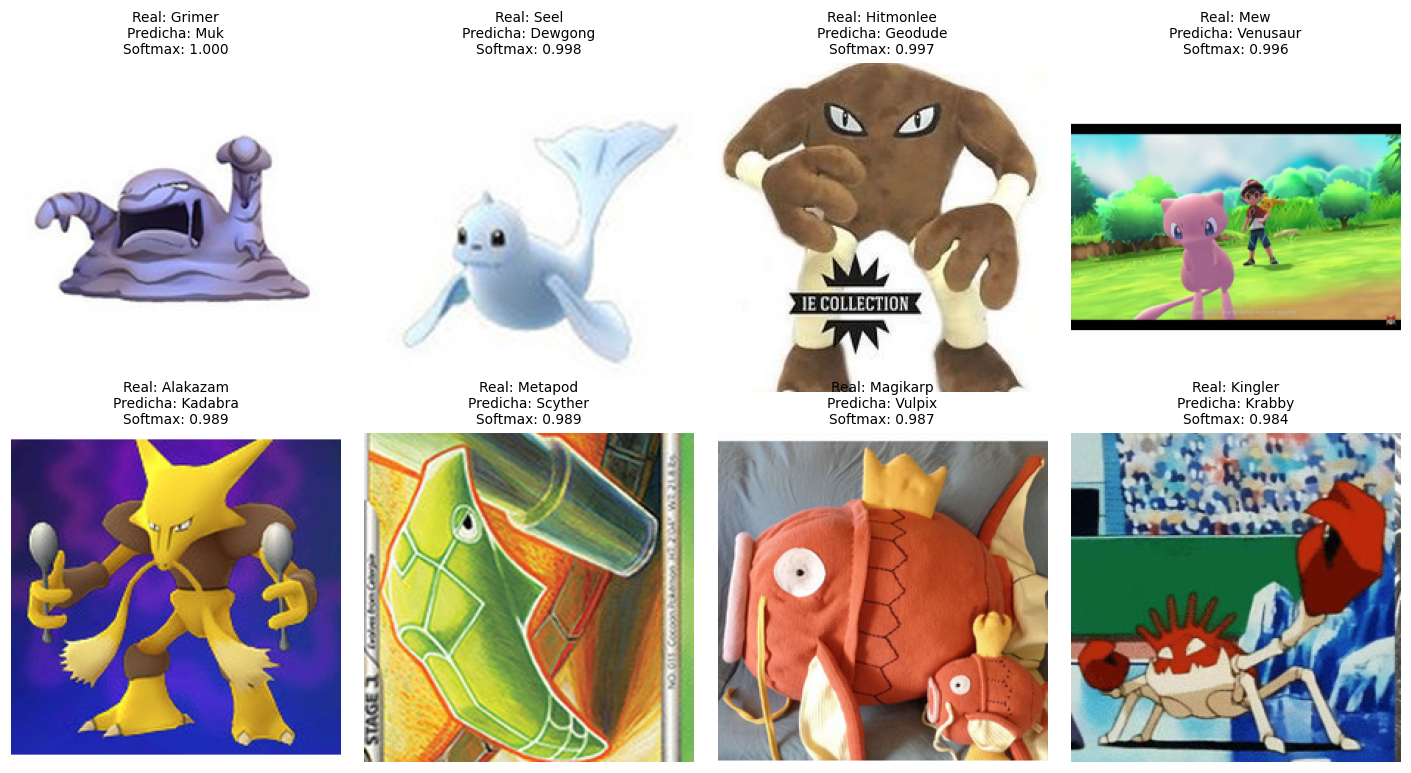

In [43]:
show_prediction_errors(
    split_frames[ANALYSIS_SPLIT], predictions_by_split[ANALYSIS_SPLIT],
    class_names, DATA_DIR,
)

### **9. Exportación del Modelo Final**

In [44]:
def export_model_package(model, class_names, results, export_dir, zip_path):
    """Guardar el modelo, sus resultados y las clases en un paquete ZIP."""
    export_dir.mkdir(parents=True, exist_ok=True)
    zip_path.parent.mkdir(parents=True, exist_ok=True)

    # Guardar la arquitectura y los pesos.
    model_path = export_dir / "final_model.keras"
    model.save(model_path)

    # Guardar los archivos de documentación.
    json_files = {
        "class_names.json": class_names,
        "training_results.json": results,
    }
    for filename, content in json_files.items():
        path = export_dir / filename
        path.write_text(
            json.dumps(content, ensure_ascii=False, indent=2),
            encoding="utf-8",
        )

    # Empaquetar únicamente los tres archivos de exportación.
    export_names = [model_path.name, *json_files]
    with ZipFile(zip_path, "w", compression=ZIP_DEFLATED) as archive:
        for filename in export_names:
            archive.write(export_dir / filename, arcname=filename)

    with ZipFile(zip_path) as archive:
        if archive.testzip() is not None:
            raise RuntimeError("El ZIP contiene un archivo dañado.")

    return model_path


def verify_saved_model(model, model_path, images):
    """Comprobar que guardar y cargar conserva las predicciones."""
    reloaded_model = tf.keras.models.load_model(model_path, compile=False)

    expected = model(images, training=False).numpy()
    obtained = reloaded_model(images, training=False).numpy()

    np.testing.assert_allclose(expected, obtained, rtol=1e-5, atol=1e-6)

In [45]:
def collect_final_results(model, fit_results):
    """Reunir configuración, decisiones experimentales y evaluación final."""
    fine = fit_results["phases"]["fine_tuning"]
    return {
        "model": "ResNet50", "model_name": model.name, "status": "final_model_test_evaluated",
        "dataset_package": DATASET_ZIP.name, "manifest_sha256": manifest_sha256,
        "protocol": fit_results["protocol"], "source": fit_results["source"],
        "experiment_decisions": EXPERIMENT_DECISIONS,
        "selection_metric": "validation_f1_macro", "checkpoint_monitor": "val_loss",
        "parameters": model.count_params(),
        "trainable_parameters": int(sum(np.prod(weight.shape) for weight in model.trainable_weights)),
        "best_epoch": fine["best_epoch"], "epochs_completed": fine["epochs_completed"],
        "training_seconds": fit_results["training_seconds"],
        "phases": fit_results["phases"], "history": fine["history"],
        "evaluation_tensorflow_version": tf.__version__, "metrics": evaluation_metrics,
        "validation_classification_report": reports_by_split["val"],
        "test_classification_report": reports_by_split["test"],
        "validation_confusion_matrix": matrices_by_split["val"].tolist(),
        "test_confusion_matrix": matrices_by_split["test"].tolist(),
    }

In [46]:
training_results = collect_final_results(selected_model, fit_results)
model_zip = RUN_DIR / "final_model.zip"
model_path = export_model_package(
    selected_model, class_names, training_results, EXPORT_DIR, model_zip
)
verification_images, _ = next(iter(val_ds))
verify_saved_model(selected_model, model_path, verification_images)
print(f"Exportación verificada: {model_zip}")
print(f"Tamaño: {model_zip.stat().st_size / 1024**2:.2f} MiB")

Exportación verificada: /content/pokemon_project/20261104T024855337360Z/final_model.zip
Tamaño: 84.63 MiB


In [47]:
DOWNLOAD_MODEL_PACKAGE = True

if DOWNLOAD_MODEL_PACKAGE:
    try:
        from google.colab import files
    except ImportError:
        print(f"Fuera de Colab, copiar el ZIP desde: {model_zip}")
    else:
        files.download(str(model_zip))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>